#Polars

In [ ]:
##Polars
import polars as pl

df = pl.DataFrame({
    'vendedor':  ['Ana', 'Luis', 'Maria', 'Carlos'],
    'region':    ['Norte', 'Sur', 'Norte', 'Sur'],
    'ventas':    [125000, 98000, 156000, 87000],
    'comision':  [0.12, 0.10, 0.15, 0.10],
})

df.dtypes
df.describe()

df_texto = pl.DataFrame({'valor': ['0.100', '250', '80', '430']})
df_numerico = df_texto.with_columns(pl.col('valor').cast(pl.Float32))  # '100' → 100 como entero)

df_numerico.schema
df_numerico
df.null_count()

df_optim = df.with_columns(
pl.col("comision").cast(pl.Float32).alias("n_comision"),
pl.sum_horizontal(pl.col("ventas", "comision")).alias("suma"),
(pl.col("ventas") + pl.col("ventas")).alias("suma2")
)

df_optim.schema
df.with_columns(pl.col("region").str.to_lowercase(),
pl.col("comision") + 1
)

vendedor,region,ventas,comision
str,str,i64,f64
"""Ana""","""norte""",125000,1.12
"""Luis""","""sur""",98000,1.1
"""Maria""","""norte""",156000,1.15
"""Carlos""","""sur""",87000,1.1


In [ ]:

import polars as pl

df = pl.DataFrame({
    'vendedor':  ['Ana', 'Luis', 'Maria', 'Carlos', 'Sofia', 'Pedro'],
    'region':    ['Norte', 'Sur', 'Norte', 'Sur', 'Norte', 'Sur'],
    'ventas':    [12000, 9800, 15600, 8700, 14500, None],
    'clientes':  [8, 6, 10, 5, 9, 7],
})

# ── sort() ascendente y descendente ──────────────────────────────────────
# De mayor a menor venta, nulos al final
ranking = df.sort('ventas', descending=True, nulls_last=True)
print('Ranking de ventas (mayor primero):')
print(ranking)

# ── sort() por multiples columnas ─────────────────────────────────────────
# Primero por region (A→Z), luego por ventas (mayor→menor) dentro de cada region
por_region_ventas = df.sort(['region', 'ventas'], descending=[False, True])
print('\nOrdenado por region (asc) y ventas (desc):')
print(por_region_ventas)

# ── Obtener el mejor vendedor por region (con group_by) ───────────────────
# sort_by() dentro de agg() ordena los valores del grupo antes de tomar el ultimo
mejor_por_region = (
    df
    .group_by('region')
    .agg(
        pl.col('ventas').sum().alias('total_ventas'),
        # sort_by('ventas') ordena los vendedores del grupo por ventas
        # .last() toma el ultimo = el de mayor venta
        pl.col('vendedor').sort_by('ventas').last().alias('mejor_vendedor'),
        pl.col('ventas').sort_by('ventas').last().alias('mejor_venta'),
    )
    .sort('region')
)
print('\nMejor vendedor por region:')
print(mejor_por_region)

# ── rank(): asignar posicion en el ranking ────────────────────────────────
# rank(descending=True): rango 1 = mayor valor; method='dense' = sin huecos
df_con_rank = df.with_columns(
    pl.col('ventas').rank(method='dense', descending=True).alias('posicion'),
).sort('posicion', nulls_last=True)
print('\nRanking de vendedores:')
print(df_con_rank.select('vendedor', 'ventas', 'posicion'))

Ranking de ventas (mayor primero):
shape: (6, 4)
┌──────────┬────────┬────────┬──────────┐
│ vendedor ┆ region ┆ ventas ┆ clientes │
│ ---      ┆ ---    ┆ ---    ┆ ---      │
│ str      ┆ str    ┆ i64    ┆ i64      │
╞══════════╪════════╪════════╪══════════╡
│ Maria    ┆ Norte  ┆ 15600  ┆ 10       │
│ Sofia    ┆ Norte  ┆ 14500  ┆ 9        │
│ Ana      ┆ Norte  ┆ 12000  ┆ 8        │
│ Luis     ┆ Sur    ┆ 9800   ┆ 6        │
│ Carlos   ┆ Sur    ┆ 8700   ┆ 5        │
│ Pedro    ┆ Sur    ┆ null   ┆ 7        │
└──────────┴────────┴────────┴──────────┘

Ordenado por region (asc) y ventas (desc):
shape: (6, 4)
┌──────────┬────────┬────────┬──────────┐
│ vendedor ┆ region ┆ ventas ┆ clientes │
│ ---      ┆ ---    ┆ ---    ┆ ---      │
│ str      ┆ str    ┆ i64    ┆ i64      │
╞══════════╪════════╪════════╪══════════╡
│ Maria    ┆ Norte  ┆ 15600  ┆ 10       │
│ Sofia    ┆ Norte  ┆ 14500  ┆ 9        │
│ Ana      ┆ Norte  ┆ 12000  ┆ 8        │
│ Pedro    ┆ Sur    ┆ null   ┆ 7        │
│ Luis     

In [ ]:
import polars as pl

# ── Crear datos de ejemplo ────────────────────────────────────────────────
import random
random.seed(0)
n = 5000
df = pl.DataFrame({
    'id':       list(range(1, n+1)),
    'pais':     [random.choice(['Mexico', 'Colombia', 'Argentina']) for _ in range(n)],
    'col_a':    [random.random() for _ in range(n)],
    'col_b':    [random.random() for _ in range(n)],
    'ventas':   [random.randint(1000, 50000) for _ in range(n)],
    'col_c':    [random.random() for _ in range(n)],
    'region':   [random.choice(['Norte', 'Sur', 'Centro']) for _ in range(n)],
    'col_d':    [random.random() for _ in range(n)],
})
df.write_parquet('datos.parquet')

# ── Ver el plan SIN optimizar ────────────────────────────────────────────
# Este es el plan 'logico' que escribiste
plan = (
    pl.scan_parquet('datos.parquet')
    .filter(pl.col('pais') == 'Mexico')       # filtro de filas
    .select('id', 'ventas', 'region')          # solo 3 de 8 columnas
    .group_by('region')
    .agg(pl.col('ventas').sum())
)

print('=== Plan LOGICO (sin optimizar) ===')
print(plan.explain(optimized=False))

print('\n=== Plan OPTIMIZADO (lo que Polars realmente ejecuta) ===')
print(plan.explain())  # observa como el filtro y proyeccion se 'empujan' al inicio

# ── Ejecutar el plan optimizado ──────────────────────────────────────────
resultado = plan.collect()
print('\nResultado final:')
print(resultado.sort('region'))

=== Plan LOGICO (sin optimizar) ===
AGGREGATE[maintain_order: false]
  [col("ventas").sum()] BY [col("region")]
  FROM
  SELECT [col("id"), col("ventas"), col("region")]
    FILTER [(col("pais")) == ("Mexico")]
    FROM
      Parquet SCAN [datos.parquet]
      PROJECT */8 COLUMNS
      ESTIMATED ROWS: 5000

=== Plan OPTIMIZADO (lo que Polars realmente ejecuta) ===
AGGREGATE[maintain_order: false]
  [col("ventas").sum()] BY [col("region")]
  FROM
  simple π 2/2 ["ventas", "region"]
    Parquet SCAN [datos.parquet]
    PROJECT 3/8 COLUMNS
    SELECTION: [(col("pais")) == ("Mexico")]
    ESTIMATED ROWS: 5000

Resultado final:
shape: (3, 2)
┌────────┬──────────┐
│ region ┆ ventas   │
│ ---    ┆ ---      │
│ str    ┆ i64      │
╞════════╪══════════╡
│ Centro ┆ 14355151 │
│ Norte  ┆ 13815716 │
│ Sur    ┆ 14797476 │
└────────┴──────────┘


In [ ]:
lz_df = pl.scan_csv(f"{Data_dir}/Raw_Data/synthetic_dataset_nonlinear_v2.csv")
plan = lz_df.filter(pl.col("num_0") < 5)
plan.explain()
res_lz_df = plan.collect()
res_lz_df.shape

(3076, 22)

#0. Importing Libraries

In [1]:
pip install fg-data-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.5/400.5 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.3/106.3 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.3 MB/s eta 0:00:00


In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint
import joblib

from itertools import combinations
from data_profiling import ProfileReport
from scipy.stats import pearsonr, spearmanr, shapiro, f_oneway, kruskal
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.feature_selection import mutual_info_regression

from time import time
from sklearn.model_selection import train_test_split, RepeatedKFold, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error, max_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

In [3]:
# External files
from google.colab import drive, files
drive.mount('/content/drive')

disk_dir = "/content/drive/MyDrive/Data Science Tests/Test File/General_Template"
Data_dir = f"{disk_dir}/Data"
Output_dir = f"{disk_dir}/Output"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# ============================================================
# Exporting csv file to be converted to a pandas dataframe

print("\n=============== Importing Dataframe ===============")

Original_DF = pd.read_csv(f"{Data_dir}/Raw_Data/synthetic_dataset_nonlinear_v2.csv")

print(Original_DF.shape)
Original_DF.head()


=============== Importing Dataframe ===============
(3080, 22)


,num_0,num_1,num_2,num_3,num_4,num_5,num_6,num_7,num_8,num_9,...,cat_str_2,cat_str_3,cat_str_4,cat_num_0,cat_num_1,cat_num_2,cat_num_3,cat_num_4,target_regression,target_classification
0,-1.085631,-0.585778,0.363051,2.149923,-3.000474,2.268910,5.839042,2.468190,-6.967709,-6.272482,...,A,B,C,2.0,0.0,1.0,1.0,2.0,-10.974592,0
1,0.997345,0.792467,-3.837686,-0.610869,-1.308478,4.213043,0.871615,3.676469,-3.653496,-1.439133,...,B,B,D,2.0,0.0,0.0,1.0,3.0,-0.735130,0
2,0.282978,1.525868,-0.716573,0.745080,2.516339,-2.790773,0.695870,0.936310,1.290001,-0.117195,...,B,D,B,0.0,3.0,2.0,1.0,2.0,2.286754,0
3,-1.506295,1.133359,0.315815,-1.029796,-2.414573,0.383934,0.978251,-6.195238,1.526014,-5.337352,...,B,A,C,2.0,1.0,0.0,0.0,0.0,-2.341131,0
4,-0.578600,2.476140,1.003784,-2.875433,-1.016609,0.139383,-3.924139,3.708745,4.634781,-1.189896,...,C,D,A,3.0,2.0,3.0,2.0,1.0,2.111496,1


In [5]:
General_DF = Original_DF.copy()

# 1. Exploratory Data Analysis

In [6]:
# Checking dataframe info and data type
General_DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3080 entries, 0 to 3079
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_0                  3080 non-null   float64
 1   num_1                  3080 non-null   float64
 2   num_2                  3080 non-null   float64
 3   num_3                  3080 non-null   float64
 4   num_4                  3080 non-null   float64
 5   num_5                  3080 non-null   float64
 6   num_6                  3080 non-null   float64
 7   num_7                  3080 non-null   float64
 8   num_8                  3080 non-null   float64
 9   num_9                  3080 non-null   float64
 10  cat_str_0              3080 non-null   object 
 11  cat_str_1              3080 non-null   object 
 12  cat_str_2              3080 non-null   object 
 13  cat_str_3              3080 non-null   object 
 14  cat_str_4              3080 non-null   object 
 15  cat_

##1.1 Data Completeness

In [7]:
# Verifying if dataframe has null values
print(30*"=")
print("Exploring null values:")
print(General_DF.isnull().sum())

# Exploring duplicates
print(30*"=")
print("\nExploring duplicated values:")
print(General_DF.duplicated().sum())

Exploring null values:
num_0                    0
num_1                    0
num_2                    0
num_3                    0
num_4                    0
num_5                    0
num_6                    0
num_7                    0
num_8                    0
num_9                    0
cat_str_0                0
cat_str_1                0
cat_str_2                0
cat_str_3                0
cat_str_4                0
cat_num_0                0
cat_num_1                0
cat_num_2                0
cat_num_3                0
cat_num_4                0
target_regression        0
target_classification    0
dtype: int64

Exploring duplicated values:
80


In [8]:
# Deleting duplicates and null values

General_DF = General_DF.dropna()

General_DF = General_DF.drop_duplicates()
General_DF

,num_0,num_1,num_2,num_3,num_4,num_5,num_6,num_7,num_8,num_9,...,cat_str_2,cat_str_3,cat_str_4,cat_num_0,cat_num_1,cat_num_2,cat_num_3,cat_num_4,target_regression,target_classification
0,-1.085631,-0.585778,0.363051,2.149923,-3.000474,2.268910,5.839042,2.468190,-6.967709,-6.272482,...,A,B,C,2.0,0.0,1.0,1.0,2.0,-10.974592,0
1,0.997345,0.792467,-3.837686,-0.610869,-1.308478,4.213043,0.871615,3.676469,-3.653496,-1.439133,...,B,B,D,2.0,0.0,0.0,1.0,3.0,-0.735130,0
2,0.282978,1.525868,-0.716573,0.745080,2.516339,-2.790773,0.695870,0.936310,1.290001,-0.117195,...,B,D,B,0.0,3.0,2.0,1.0,2.0,2.286754,0
3,-1.506295,1.133359,0.315815,-1.029796,-2.414573,0.383934,0.978251,-6.195238,1.526014,-5.337352,...,B,A,C,2.0,1.0,0.0,0.0,0.0,-2.341131,0
4,-0.578600,2.476140,1.003784,-2.875433,-1.016609,0.139383,-3.924139,3.708745,4.634781,-1.189896,...,C,D,A,3.0,2.0,3.0,2.0,1.0,2.111496,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,-0.075335,-0.027964,0.809999,-1.669817,3.038092,-0.893647,-1.405066,2.607688,1.850734,-5.284638,...,B,D,D,0.0,0.0,0.0,2.0,3.0,-7.210566,1
2996,-0.946199,2.222731,1.815167,2.658374,5.725765,2.741503,-4.181793,1.213419,0.212602,1.592854,...,C,A,B,1.0,0.0,2.0,0.0,1.0,15.368051,1
2997,2.040432,1.722392,-1.046365,-4.536812,-4.024562,1.664126,0.500789,9.121383,4.311721,-4.235485,...,B,C,B,0.0,3.0,2.0,3.0,1.0,19.956086,1
2998,1.015917,-0.585992,0.025434,-0.685598,2.143194,-3.022689,0.178536,-2.767532,-0.390596,-1.752622,...,C,D,B,3.0,0.0,2.0,1.0,0.0,0.081292,1


In [9]:
# Converting int to float

cols = General_DF.columns
cols2int = list(cols[15:-2]) + list(cols[-1:])

General_DF[cols2int] = General_DF[cols2int].astype(int)

In [10]:
# Separating quantitative and qualitative features

# Quantitative features
quant_ft = list(General_DF.select_dtypes(include = np.number).columns)#[:-1] # Excluding the target variable

# Qualitative/Categorical features
qual_ft = list(General_DF.select_dtypes(exclude = np.number).columns)#[:-1] # Excluding the target variable

quant_ft, qual_ft

(['num_0',
  'num_1',
  'num_2',
  'num_3',
  'num_4',
  'num_5',
  'num_6',
  'num_7',
  'num_8',
  'num_9',
  'cat_num_0',
  'cat_num_1',
  'cat_num_2',
  'cat_num_3',
  'cat_num_4',
  'target_regression',
  'target_classification'],
 ['cat_str_0', 'cat_str_1', 'cat_str_2', 'cat_str_3', 'cat_str_4'])

In [11]:
# Modifying the lists

qual_ft = qual_ft + quant_ft[10:15] + quant_ft[-1:]
quant_ft = quant_ft[:10] + quant_ft[-2:-1]

quant_ft, qual_ft

(['num_0',
  'num_1',
  'num_2',
  'num_3',
  'num_4',
  'num_5',
  'num_6',
  'num_7',
  'num_8',
  'num_9',
  'target_regression'],
 ['cat_str_0',
  'cat_str_1',
  'cat_str_2',
  'cat_str_3',
  'cat_str_4',
  'cat_num_0',
  'cat_num_1',
  'cat_num_2',
  'cat_num_3',
  'cat_num_4',
  'target_classification'])

##1.2. Descriptive Statistics

In [12]:
# Report creation with data profiling
profile = ProfileReport(General_DF, title="Profiling Report")

In [13]:
profile

Output hidden; open in https://colab.research.google.com to view.

###1.2.1. Univariate Analyses

In [14]:
# Analyzing values function

def analyzing_data(dataframe):

    # Printing data type and unique values
    print("\n=============== Unique Values and Datatypes ===============")

    # Header
    col_names = list(dataframe.columns)

    for col in col_names:
        print(f"\n{col}")
        print(f"Total unique values: {len(dataframe[col].unique())}")
        #print(f"Values: {dataframe[col].unique()}")
        print(type(dataframe[col].to_numpy()[0]))

    # Verifying data distribution

    # Getting dataframe statistics
    print("\n=============== Dataframe Statistics ===============\n")
    print(dataframe.describe())

def vis_outliers(dataframe, features):

    print("\n=============== Data Distribution ===============\n")
    plt.figure(figsize = (17, 50))

    for i, name in enumerate(features):
        plt.subplot(15, 4,i+1)
        plt.boxplot(dataframe[f"{name}"])
        plt.title(f"{name}")

def hist_box(data, feature):

    print(f"\n\n=============== {feature} Data Distribution ===============\n")

    fig, ax = plt.subplots(1, 2, figsize = (9, 3))

    # Boxplot
    ax[0].boxplot(data[f"{feature}"])
    #sns.boxplot(data = data, y = feature, ax = ax[0], color = "orange")
    ax[0].set_title(f"{feature} Boxplot")

    # Histogram
    sns.histplot(data = data, x = feature, bins = 25, kde = True, ax = ax[1], color = "green")
    ax[1].set_title(f"{feature} Histogram")

    plt.show()


def qual_plots(feature, dataframe):

    print(f"\n\n=============== {feature} Data Distribution ===============\n")

    sns.countplot(data = dataframe, x = feature, hue = feature)
    plt.show()


def qual_ft_proportion(feature, dataframe, target):
    if feature == target:
        return dataframe[target].value_counts(normalize = True)
    return dataframe.groupby(feature)[target].value_counts(normalize = True).unstack(fill_value = 0)

def scatter_plots(feature1, feature2, dataframe):
    print(f"\n\n=============== {feature1} vs {feature2} Correlation ===============\n")
    ax = sns.scatterplot(x = feature1, y = feature2, data = dataframe)
    ax.set_title(f"{feature1} vs {feature2} Correlation")
    plt.show()

In [15]:
# Statistics
analyzing_data(General_DF)


=============== Unique Values and Datatypes ===============

num_0
Total unique values: 3000
<class 'numpy.float64'>

num_1
Total unique values: 3000
<class 'numpy.float64'>

num_2
Total unique values: 3000
<class 'numpy.float64'>

num_3
Total unique values: 3000
<class 'numpy.float64'>

num_4
Total unique values: 3000
<class 'numpy.float64'>

num_5
Total unique values: 3000
<class 'numpy.float64'>

num_6
Total unique values: 3000
<class 'numpy.float64'>

num_7
Total unique values: 3000
<class 'numpy.float64'>

num_8
Total unique values: 3000
<class 'numpy.float64'>

num_9
Total unique values: 3000
<class 'numpy.float64'>

cat_str_0
Total unique values: 16
<class 'str'>

cat_str_1
Total unique values: 26
<class 'str'>

cat_str_2
Total unique values: 18
<class 'str'>

cat_str_3
Total unique values: 19
<class 'str'>

cat_str_4
Total unique values: 18
<class 'str'>

cat_num_0
Total unique values: 5
<class 'numpy.int64'>

cat_num_1
Total unique values: 5
<class 'numpy.int64'>

cat_num_2
T

####1.2.1.1. Qualitative Features



=============== cat_str_0 Data Distribution ===============



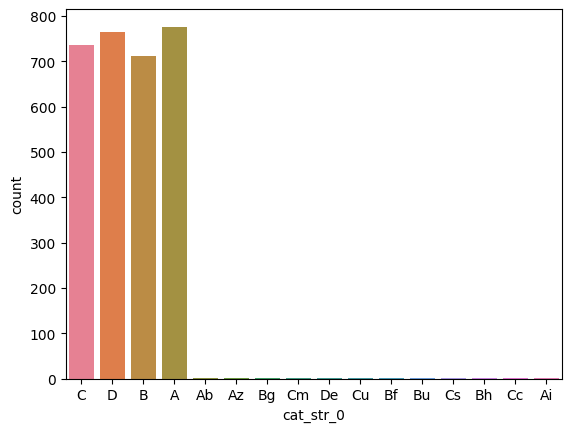

target_classification         0         1
cat_str_0                                
A                      0.458763  0.541237
Ab                     0.000000  1.000000
Ai                     0.000000  1.000000
Az                     1.000000  0.000000
B                      0.528090  0.471910
Bf                     1.000000  0.000000
Bg                     0.000000  1.000000
Bh                     1.000000  0.000000
Bu                     1.000000  0.000000
C                      0.555102  0.444898
Cc                     0.000000  1.000000
Cm                     0.000000  1.000000
Cs                     1.000000  0.000000
Cu                     1.000000  0.000000
D                      0.593464  0.406536
De                     0.000000  1.000000


=============== cat_str_1 Data Distribution ===============



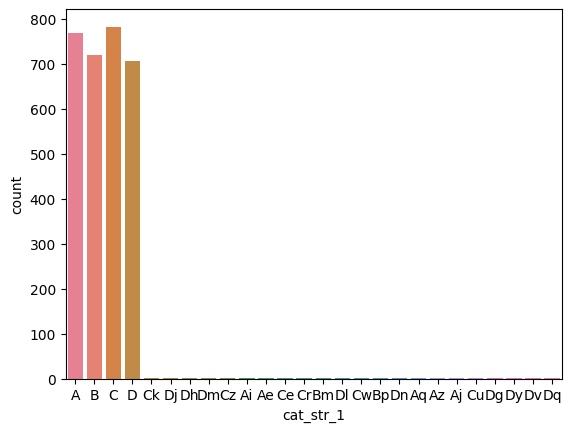

target_classification         0         1
cat_str_1                                
A                      0.552083  0.447917
Ae                     0.000000  1.000000
Ai                     1.000000  0.000000
Aj                     1.000000  0.000000
Aq                     0.000000  1.000000
Az                     1.000000  0.000000
B                      0.523611  0.476389
Bm                     1.000000  0.000000
Bp                     1.000000  0.000000
C                      0.518519  0.481481
Ce                     0.000000  1.000000
Ck                     1.000000  0.000000
Cr                     0.000000  1.000000
Cu                     1.000000  0.000000
Cw                     1.000000  0.000000
Cz                     0.000000  1.000000
D                      0.538244  0.461756
Dg                     1.000000  0.000000
Dh                     1.000000  0.000000
Dj                     0.000000  1.000000
Dl                     0.000000  1.000000
Dm                     1.000000  0

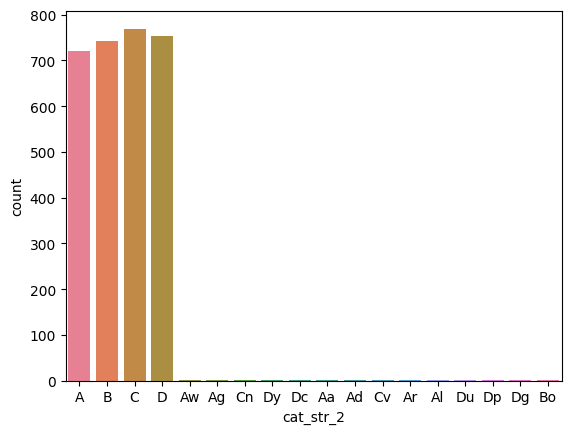

target_classification         0         1
cat_str_2                                
A                      0.551389  0.448611
Aa                     1.000000  0.000000
Ad                     1.000000  0.000000
Ag                     1.000000  0.000000
Al                     0.000000  1.000000
Ar                     1.000000  0.000000
Aw                     1.000000  0.000000
B                      0.527591  0.472409
Bo                     0.000000  1.000000
C                      0.520156  0.479844
Cn                     0.000000  1.000000
Cv                     0.000000  1.000000
D                      0.534483  0.465517
Dc                     1.000000  0.000000
Dg                     0.000000  1.000000
Dp                     0.000000  1.000000
Du                     1.000000  0.000000
Dy                     1.000000  0.000000


=============== cat_str_3 Data Distribution ===============



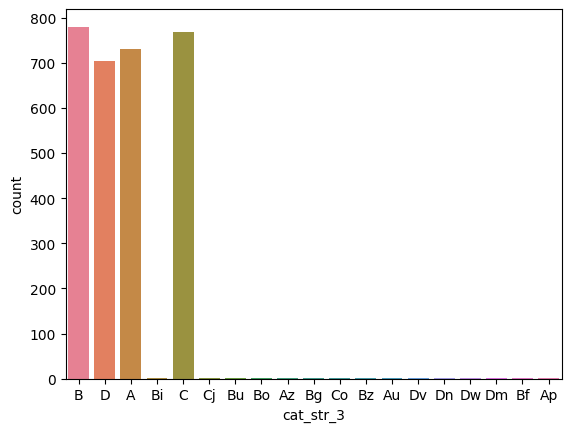

target_classification         0         1
cat_str_3                                
A                      0.510260  0.489740
Ap                     1.000000  0.000000
Au                     1.000000  0.000000
Az                     1.000000  0.000000
B                      0.551282  0.448718
Bf                     1.000000  0.000000
Bg                     1.000000  0.000000
Bi                     1.000000  0.000000
Bo                     1.000000  0.000000
Bu                     1.000000  0.000000
Bz                     1.000000  0.000000
C                      0.540962  0.459038
Cj                     1.000000  0.000000
Co                     0.000000  1.000000
D                      0.521307  0.478693
Dm                     1.000000  0.000000
Dn                     0.000000  1.000000
Dv                     1.000000  0.000000
Dw                     1.000000  0.000000


=============== cat_str_4 Data Distribution ===============



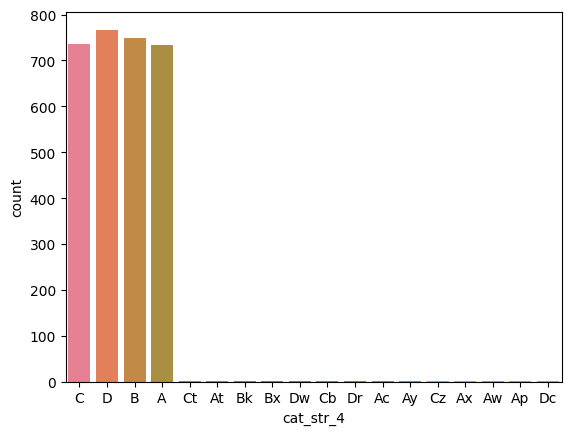

target_classification         0         1
cat_str_4                                
A                      0.561308  0.438692
Ac                     0.000000  1.000000
Ap                     0.000000  1.000000
At                     1.000000  0.000000
Aw                     1.000000  0.000000
Ax                     1.000000  0.000000
Ay                     1.000000  0.000000
B                      0.525401  0.474599
Bk                     1.000000  0.000000
Bx                     0.000000  1.000000
C                      0.529891  0.470109
Cb                     0.000000  1.000000
Ct                     0.000000  1.000000
Cz                     0.000000  1.000000
D                      0.518905  0.481095
Dc                     1.000000  0.000000
Dr                     0.000000  1.000000
Dw                     0.000000  1.000000


=============== cat_num_0 Data Distribution ===============



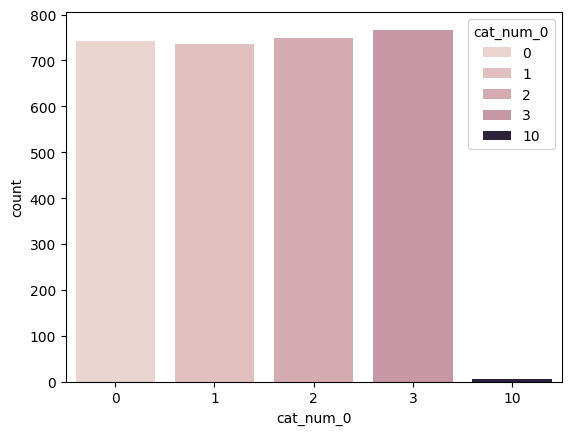

target_classification         0         1
cat_num_0                                
0                      0.530283  0.469717
1                      0.527891  0.472109
2                      0.534045  0.465955
3                      0.541069  0.458931
10                     0.500000  0.500000


=============== cat_num_1 Data Distribution ===============



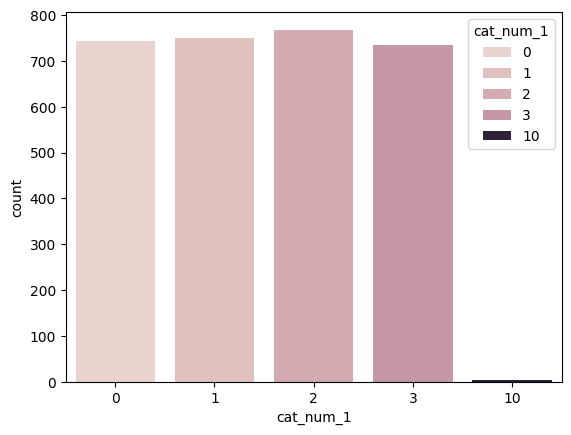

target_classification         0         1
cat_num_1                                
0                      0.551817  0.448183
1                      0.556591  0.443409
2                      0.480469  0.519531
3                      0.544959  0.455041
10                     0.750000  0.250000


=============== cat_num_2 Data Distribution ===============



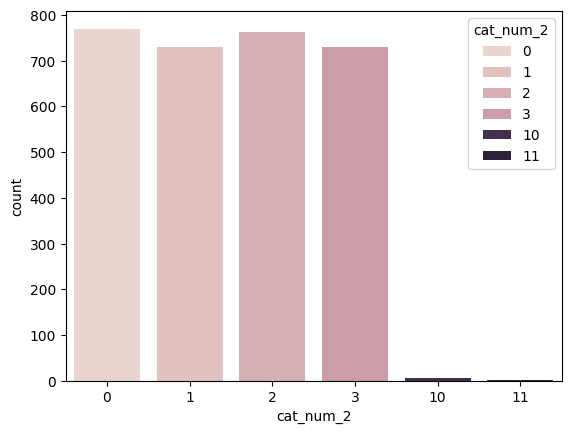

target_classification         0         1
cat_num_2                                
0                      0.537662  0.462338
1                      0.531507  0.468493
2                      0.539974  0.460026
3                      0.521918  0.478082
10                     0.666667  0.333333
11                     1.000000  0.000000


=============== cat_num_3 Data Distribution ===============



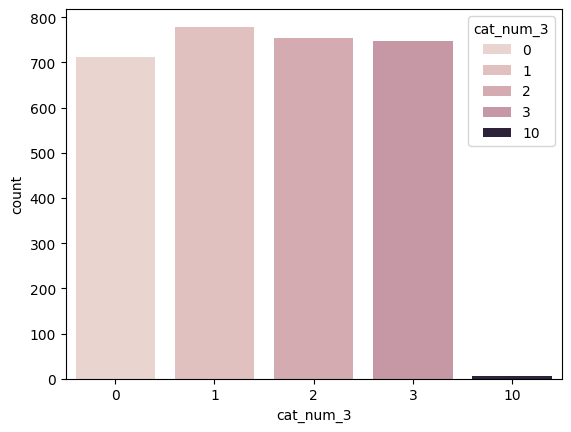

target_classification         0         1
cat_num_3                                
0                      0.531646  0.468354
1                      0.507060  0.492940
2                      0.540397  0.459603
3                      0.553476  0.446524
10                     0.714286  0.285714


=============== cat_num_4 Data Distribution ===============



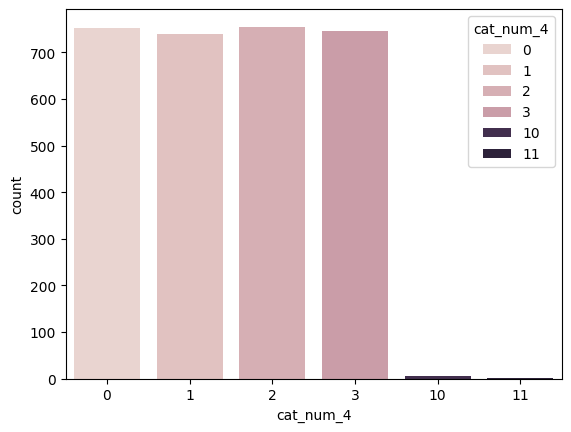

target_classification         0         1
cat_num_4                                
0                      0.537849  0.462151
1                      0.518268  0.481732
2                      0.544371  0.455629
3                      0.529491  0.470509
10                     0.833333  0.166667
11                     1.000000  0.000000


=============== target_classification Data Distribution ===============



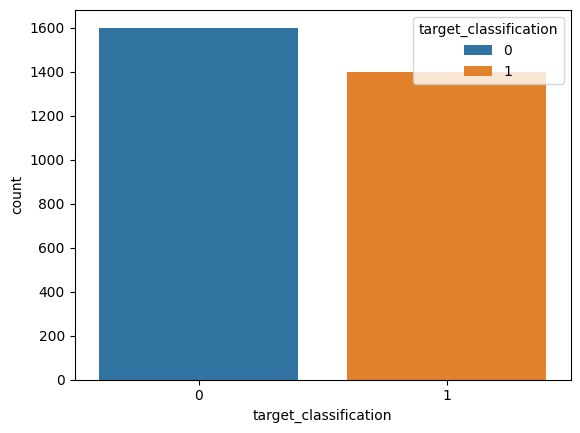

target_classification
0    0.533333
1    0.466667
Name: proportion, dtype: float64


In [16]:
# Feature proportion in target variable
# Categorical features

for feature in qual_ft:
    qual_plots(feature, General_DF)
    print(qual_ft_proportion(feature, General_DF, "target_classification"))

####1.2.1.2. Quantitative Features



=============== num_0 Data Distribution ===============



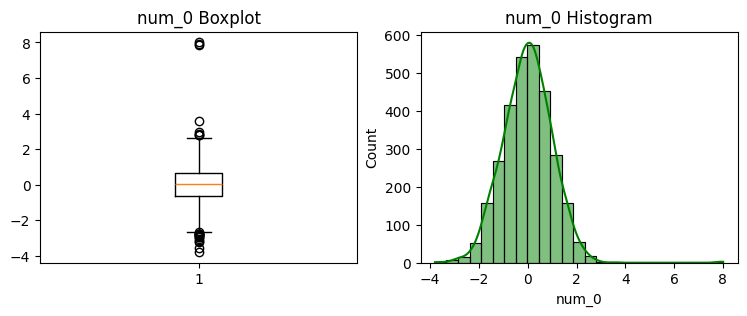



=============== num_1 Data Distribution ===============



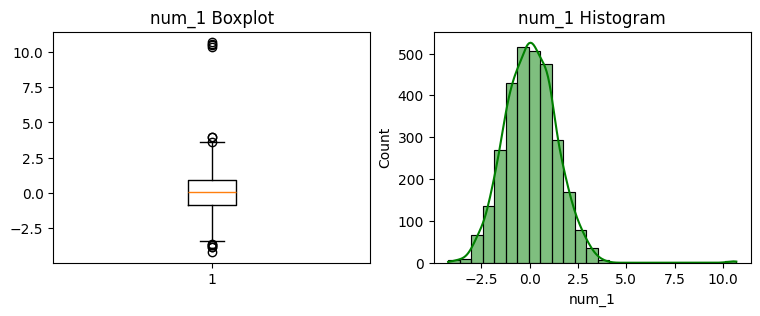



=============== num_2 Data Distribution ===============



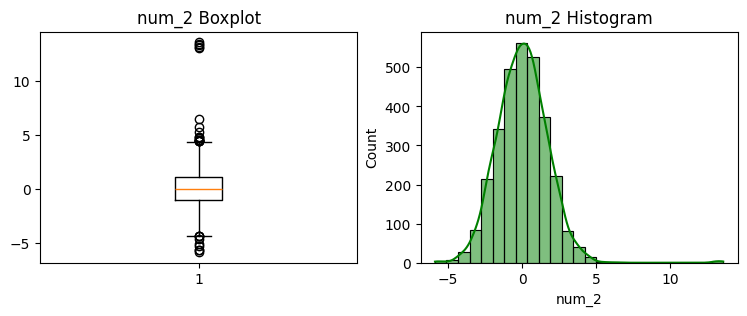



=============== num_3 Data Distribution ===============



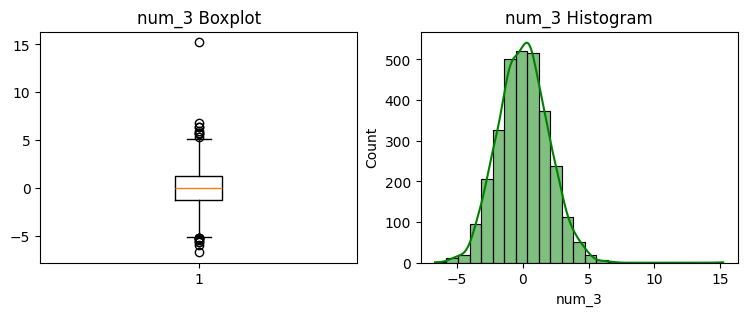



=============== num_4 Data Distribution ===============



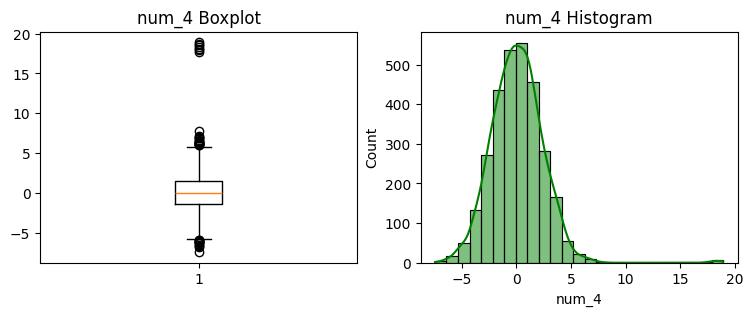



=============== num_5 Data Distribution ===============



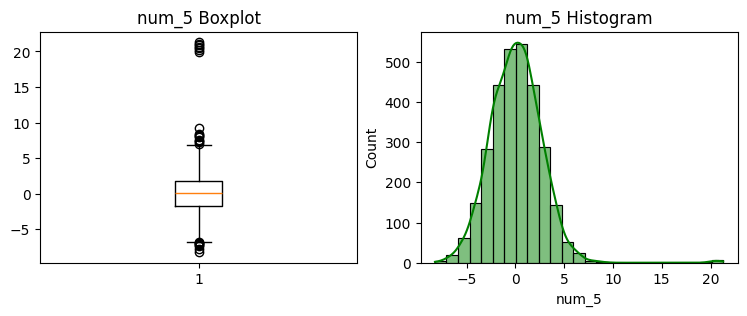



=============== num_6 Data Distribution ===============



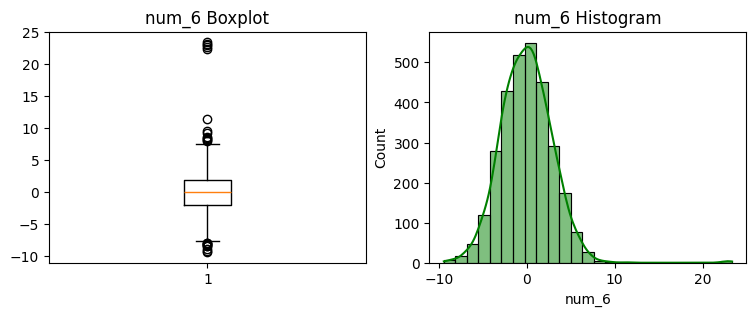



=============== num_7 Data Distribution ===============



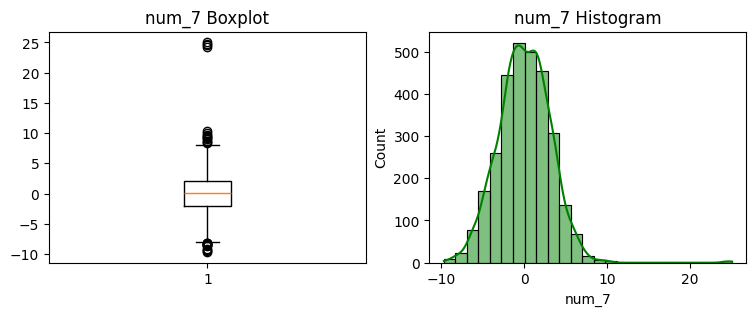



=============== num_8 Data Distribution ===============



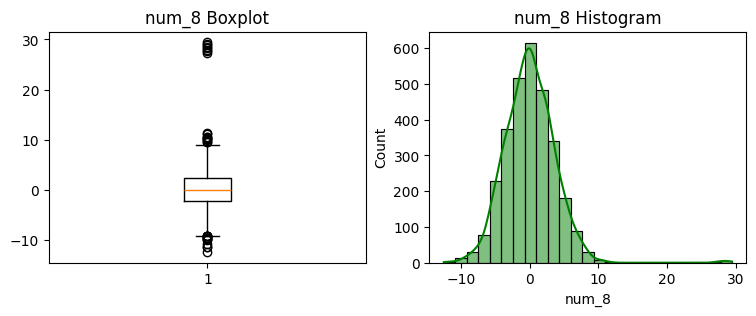



=============== num_9 Data Distribution ===============



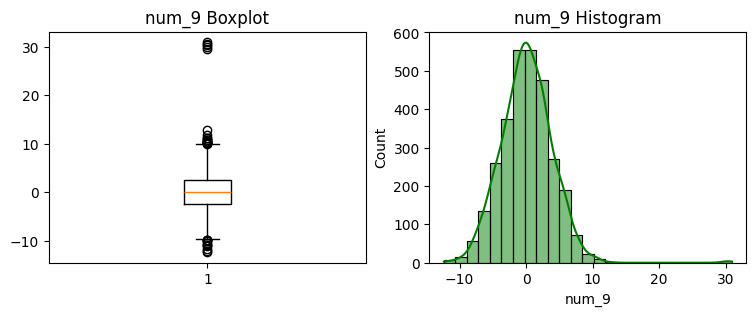



=============== target_regression Data Distribution ===============



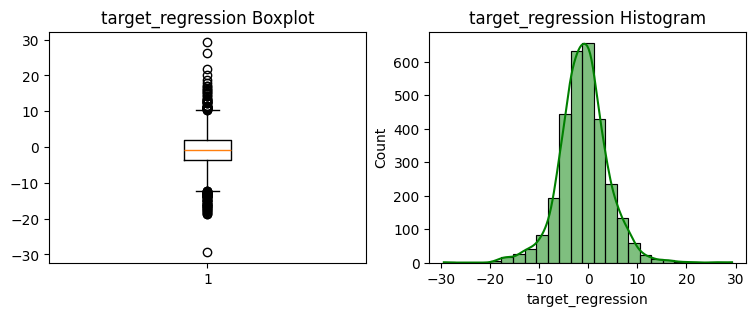

In [17]:
# Visualaztion data distribution (Outliers and histograms)
for feature in quant_ft:
    hist_box(General_DF, feature)

####1.2.1.3. Outliers

In [18]:
# Dealing with Outliers
# Use of winsorization approach to hangle outliers

# Winsorizing per feature capping the values to the corresponding Max. value

for feature in quant_ft[:-1]:
    # Positive values
    upper_lim = General_DF[feature].quantile(0.99)
    General_DF[feature] = np.where(General_DF[feature] > upper_lim, upper_lim, General_DF[feature])

    # Negative values
    lower_lim = General_DF[feature].quantile(0.01)
    General_DF[feature] = np.where(General_DF[feature] < lower_lim, lower_lim, General_DF[feature])



=============== num_0 Data Distribution ===============



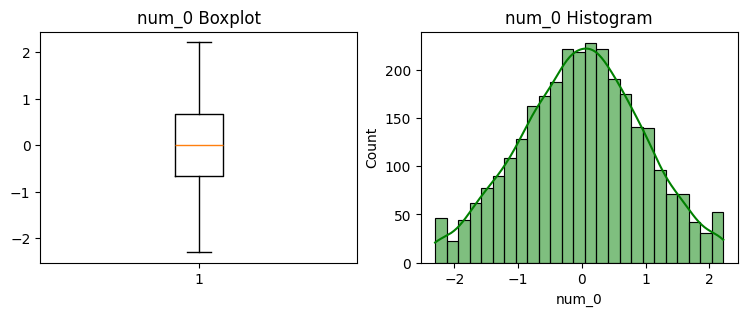



=============== num_1 Data Distribution ===============



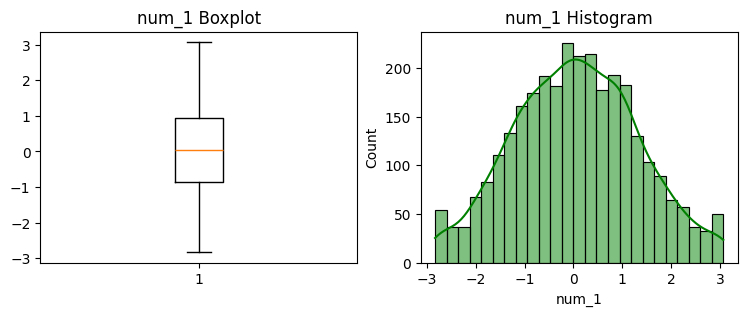



=============== num_2 Data Distribution ===============



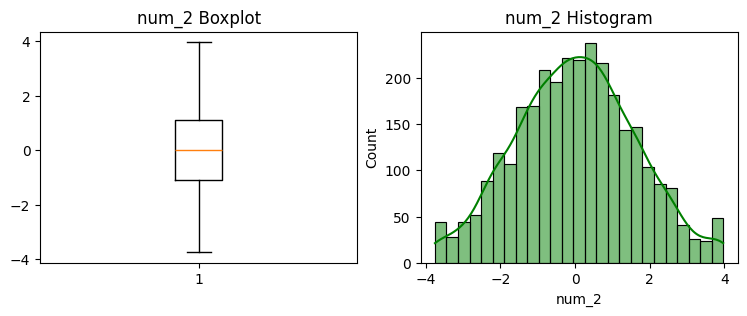



=============== num_3 Data Distribution ===============



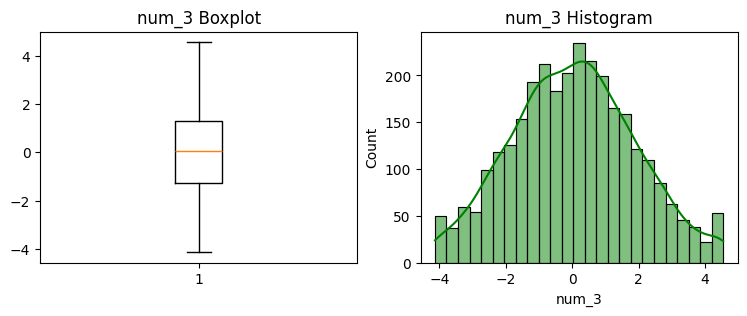



=============== num_4 Data Distribution ===============



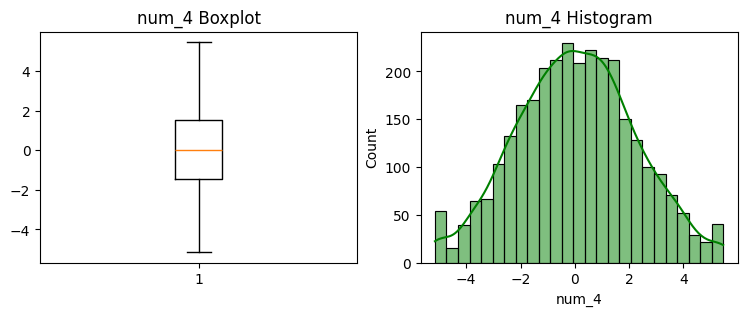



=============== num_5 Data Distribution ===============



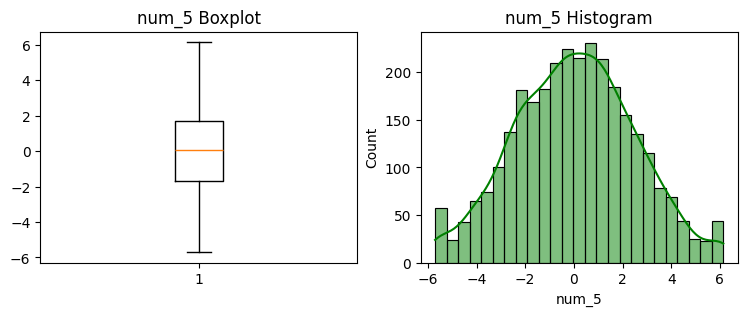



=============== num_6 Data Distribution ===============



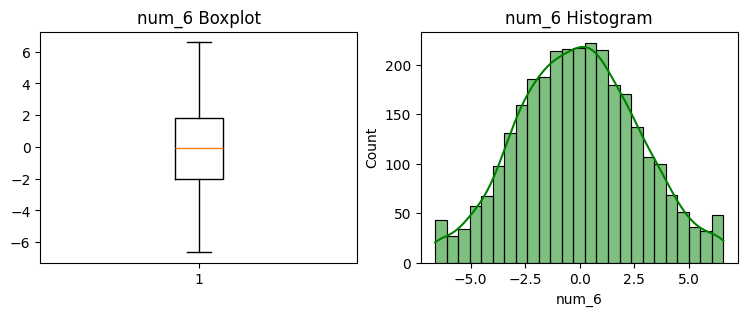



=============== num_7 Data Distribution ===============



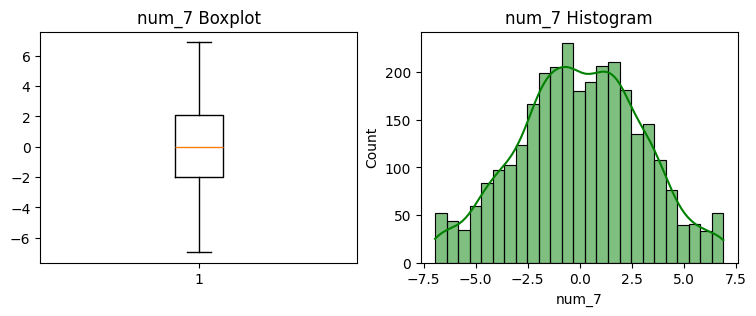



=============== num_8 Data Distribution ===============



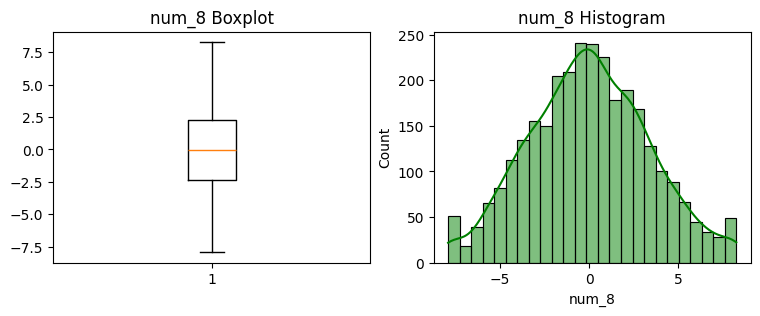



=============== num_9 Data Distribution ===============



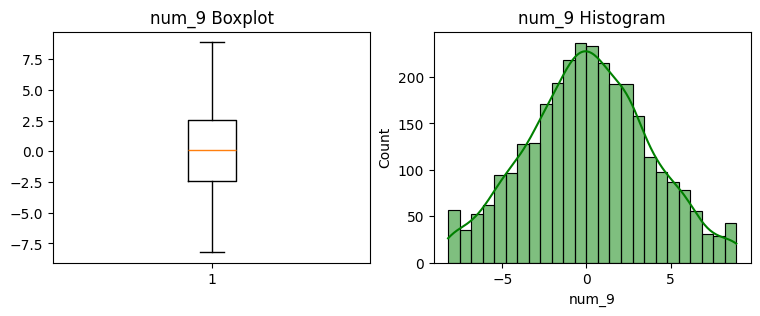



=============== target_regression Data Distribution ===============



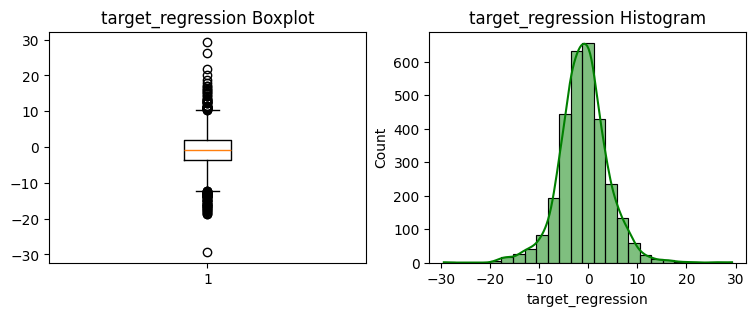

In [19]:
# Visualaztion data distribution (Outliers and histograms)
for feature in quant_ft:
    hist_box(General_DF, feature)

###1.2.2. Bivariate Analyses

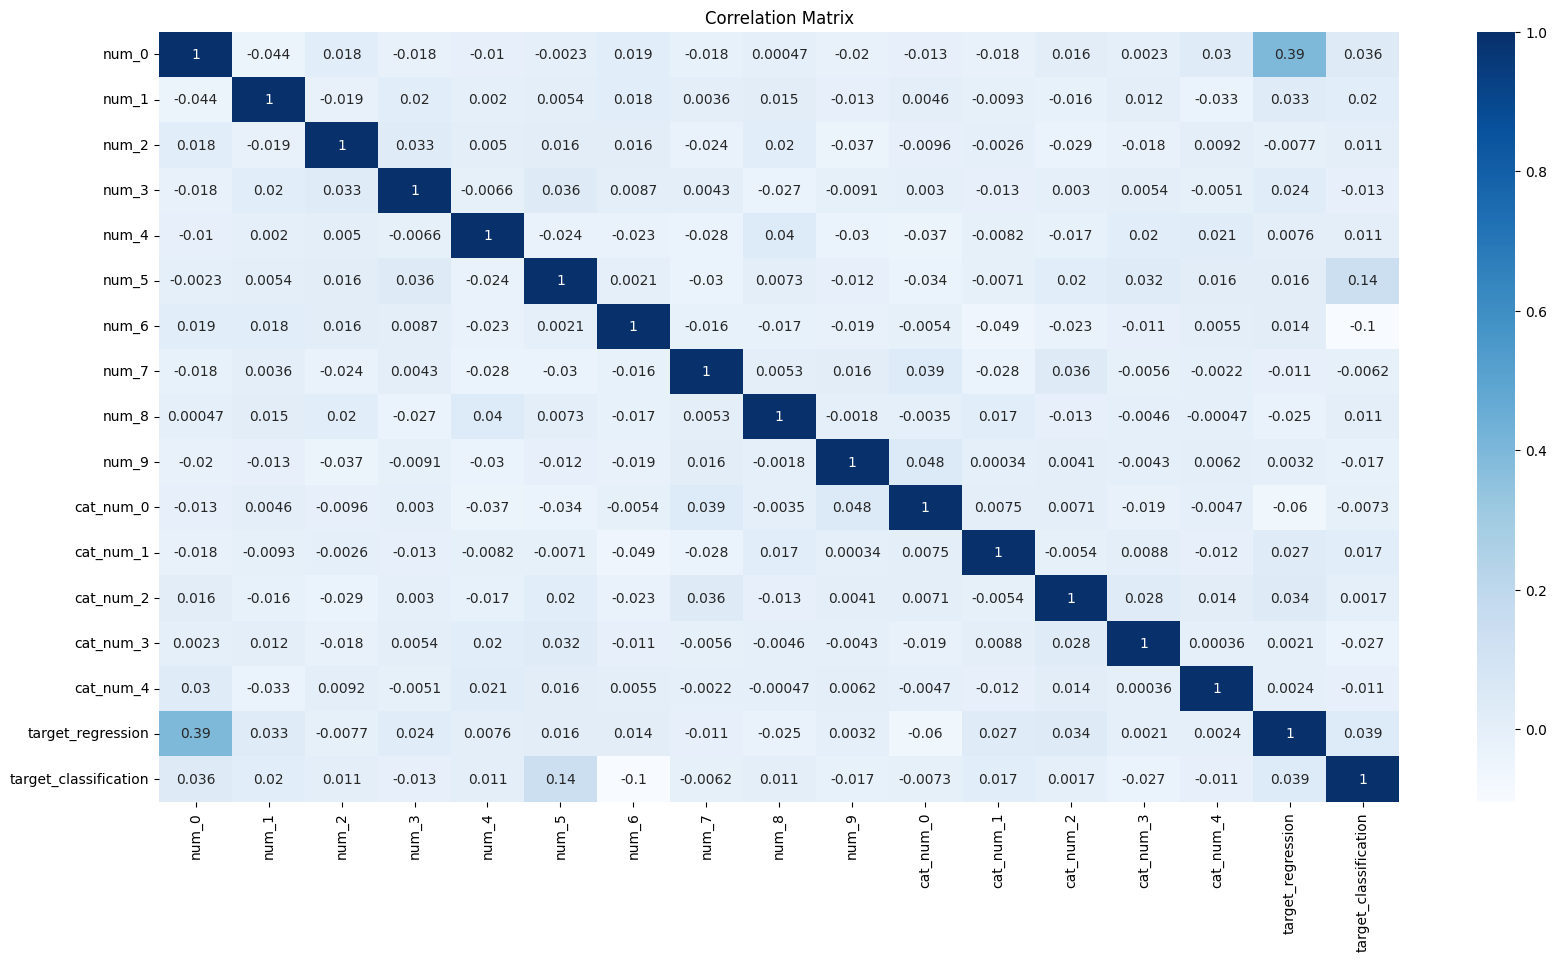

In [20]:
# Getting correlation matrix
corr_matrix = General_DF.corr(numeric_only = True)

plt.figure(figsize=(20,10))
sns.heatmap(corr_matrix, cmap = "Blues", annot = True)
plt.title("Correlation Matrix")
plt.show()

In [21]:
# Get all combinations of length 2
quant_ftpairs = list(combinations(quant_ft, 2))

# Ploting scatter graphs to verify correlation
for pair_ft in quant_ftpairs:
    scatter_plots(pair_ft[0], pair_ft[1], General_DF)

Output hidden; open in https://colab.research.google.com to view.

##1.3. Feature Selection

In [22]:
# Separating features and targets

X = General_DF.drop(columns = ["target_regression", "target_classification"])
Y_reg = General_DF["target_regression"]
Y_class = General_DF["target_classification"]


###1.3.1 Inferential Statistics

####1.3.1.1. For Numerical Features

In [23]:
# Pearson ans Spearman Linear relanship
def correlation_results(X, Y, feature):

    # Pearson for linear relationship and continuos variables
    pearson_corr, pearson_p = pearsonr(X[feature], Y)

    # Spearman for monotonic relationship and continuos and categorical variables
    spearman_corr, spearman_p = spearmanr(X[feature], Y)

    return pearson_corr, pearson_p, spearman_corr, spearman_p

#####1.3.1.1.1. Correlation and P-value correction

In [24]:
# Detailed exploration

corr_results = []

for feature in quant_ft[:-1]:
    corr_res = correlation_results(X = X, Y = Y_reg, feature = feature)

    # Saving Results
    corr_results.append({
                         "Feature": feature,
                         "Pearson Corr": corr_res[0],
                         "Pearson p-value": corr_res[1],
                         #"Spearman Corr": corr_res[2]
                         #"Spearman p-value": corr_res[3]
                        })

# Creating a DataFrame
statistical_df = pd.DataFrame(corr_results)

print("\n=== Statiatical Results ===\n")
print(statistical_df)


=== Statiatical Results ===

  Feature  Pearson Corr  Pearson p-value
0   num_0      0.392856    2.741138e-111
1   num_1      0.032711     7.322988e-02
2   num_2     -0.007724     6.723680e-01
3   num_3      0.024156     1.859359e-01
4   num_4      0.007633     6.759962e-01
5   num_5      0.016281     3.727027e-01
6   num_6      0.014291     4.339329e-01
7   num_7     -0.011368     5.336681e-01
8   num_8     -0.025270     1.664414e-01
9   num_9      0.003156     8.628363e-01


In [25]:
# P values correction
statistical_df["Pearson p-value corrected"] = multipletests(statistical_df["Pearson p-value"], method = "fdr_bh")[1] # [1] to get the p-corrected value
statistical_df["Null Hypothesis"] = multipletests(statistical_df["Pearson p-value"], method = "fdr_bh")[0] # [0] to get the bool value for null hypothesis

statistical_df.sort_values(by = "Pearson Corr", ascending = False) # Ascending sorting

,Feature,Pearson Corr,Pearson p-value,Pearson p-value corrected,Null Hypothesis
0,num_0,0.392856,2.741138e-111,2.741138e-110,True
1,num_1,0.032711,7.322988e-02,3.661494e-01,False
3,num_3,0.024156,1.859359e-01,4.648398e-01,False
5,num_5,0.016281,3.727027e-01,7.232216e-01,False
6,num_6,0.014291,4.339329e-01,7.232216e-01,False
4,num_4,0.007633,6.759962e-01,7.511069e-01,False
9,num_9,0.003156,8.628363e-01,8.628363e-01,False
2,num_2,-0.007724,6.723680e-01,7.511069e-01,False
7,num_7,-0.011368,5.336681e-01,7.511069e-01,False
8,num_8,-0.025270,1.664414e-01,4.648398e-01,False


Notes:

Observed numerical/quantitative features with correlation:
1. num_0
2. num_1
3. num_3

#####1.3.1.1.2. Mutual Information

In [26]:
# Feature Relevance for numerical features
MI_scores_conFT = mutual_info_regression(X[quant_ft[:-1]], Y_reg)

statistical_df["Mutual Info. Cont Ft"] = MI_scores_conFT

statistical_df.sort_values(by = "Mutual Info. Cont Ft", ascending = False)

,Feature,Pearson Corr,Pearson p-value,Pearson p-value corrected,Null Hypothesis,Mutual Info. Cont Ft
0,num_0,0.392856,2.741138e-111,2.741138e-110,True,0.122431
4,num_4,0.007633,6.759962e-01,7.511069e-01,False,0.102556
3,num_3,0.024156,1.859359e-01,4.648398e-01,False,0.102128
1,num_1,0.032711,7.322988e-02,3.661494e-01,False,0.031822
2,num_2,-0.007724,6.723680e-01,7.511069e-01,False,0.029431
8,num_8,-0.025270,1.664414e-01,4.648398e-01,False,0.010464
9,num_9,0.003156,8.628363e-01,8.628363e-01,False,0.004677
5,num_5,0.016281,3.727027e-01,7.232216e-01,False,0.000000
7,num_7,-0.011368,5.336681e-01,7.511069e-01,False,0.000000
6,num_6,0.014291,4.339329e-01,7.232216e-01,False,0.000000


Notes:

Observed numerical/quantitative features with mutual information:
1. num_0
2. num_4
3. num_3

#####1.3.1.1.3. Variance Inflation Factor

In [27]:
# Variance Validation

X_vif = sm.add_constant(X[quant_ft[:-1]])

statistical_df["VIF"] = [variance_inflation_factor(X_vif.values, i+1) for i in range(len(quant_ft[:-1]))]

statistical_df.sort_values(by = "VIF", ascending = False)

,Feature,Pearson Corr,Pearson p-value,Pearson p-value corrected,Null Hypothesis,Mutual Info. Cont Ft,VIF
4,num_4,0.007633,6.759962e-01,7.511069e-01,False,0.102556,1.004625
2,num_2,-0.007724,6.723680e-01,7.511069e-01,False,0.029431,1.004511
3,num_3,0.024156,1.859359e-01,4.648398e-01,False,0.102128,1.004049
0,num_0,0.392856,2.741138e-111,2.741138e-110,True,0.122431,1.003677
9,num_9,0.003156,8.628363e-01,8.628363e-01,False,0.004677,1.003567
1,num_1,0.032711,7.322988e-02,3.661494e-01,False,0.031822,1.003527
8,num_8,-0.025270,1.664414e-01,4.648398e-01,False,0.010464,1.003373
5,num_5,0.016281,3.727027e-01,7.232216e-01,False,0.000000,1.003265
7,num_7,-0.011368,5.336681e-01,7.511069e-01,False,0.000000,1.003103
6,num_6,0.014291,4.339329e-01,7.232216e-01,False,0.000000,1.002386


Notes:
1. No sign of colinarity among the observed features

####1.3.1.2. For Categorical Fetures

In [28]:
# Encoding categorical features (OHE)
X_expanded = pd.get_dummies(X)
X_expanded

,num_0,num_1,num_2,num_3,num_4,num_5,num_6,num_7,num_8,num_9,...,cat_str_4_Bk,cat_str_4_Bx,cat_str_4_C,cat_str_4_Cb,cat_str_4_Ct,cat_str_4_Cz,cat_str_4_D,cat_str_4_Dc,cat_str_4_Dr,cat_str_4_Dw
0,-1.085631,-0.585778,0.363051,2.149923,-3.000474,2.268910,5.839042,2.468190,-6.967709,-6.272482,...,False,False,True,False,False,False,False,False,False,False
1,0.997345,0.792467,-3.751272,-0.610869,-1.308478,4.213043,0.871615,3.676469,-3.653496,-1.439133,...,False,False,False,False,False,False,True,False,False,False
2,0.282978,1.525868,-0.716573,0.745080,2.516339,-2.790773,0.695870,0.936310,1.290001,-0.117195,...,False,False,False,False,False,False,False,False,False,False
3,-1.506295,1.133359,0.315815,-1.029796,-2.414573,0.383934,0.978251,-6.195238,1.526014,-5.337352,...,False,False,True,False,False,False,False,False,False,False
4,-0.578600,2.476140,1.003784,-2.875433,-1.016609,0.139383,-3.924139,3.708745,4.634781,-1.189896,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,-0.075335,-0.027964,0.809999,-1.669817,3.038092,-0.893647,-1.405066,2.607688,1.850734,-5.284638,...,False,False,False,False,False,False,True,False,False,False
2996,-0.946199,2.222731,1.815167,2.658374,5.466595,2.741503,-4.181793,1.213419,0.212602,1.592854,...,False,False,False,False,False,False,False,False,False,False
2997,2.040432,1.722392,-1.046365,-4.133457,-4.024562,1.664126,0.500789,6.890400,4.311721,-4.235485,...,False,False,False,False,False,False,False,False,False,False
2998,1.015917,-0.585992,0.025434,-0.685598,2.143194,-3.022689,0.178536,-2.767532,-0.390596,-1.752622,...,False,False,False,False,False,False,False,False,False,False


In [29]:
# Creating the new list of categorical features

new_qual_ft = list(X_expanded.select_dtypes(exclude = np.number).columns)
new_qual_ft = qual_ft[5:-1] + new_qual_ft
len(new_qual_ft)
print(new_qual_ft)
X_expanded[["cat_str_0_A", "cat_num_0"]].info()

['cat_num_0', 'cat_num_1', 'cat_num_2', 'cat_num_3', 'cat_num_4', 'cat_str_0_A', 'cat_str_0_Ab', 'cat_str_0_Ai', 'cat_str_0_Az', 'cat_str_0_B', 'cat_str_0_Bf', 'cat_str_0_Bg', 'cat_str_0_Bh', 'cat_str_0_Bu', 'cat_str_0_C', 'cat_str_0_Cc', 'cat_str_0_Cm', 'cat_str_0_Cs', 'cat_str_0_Cu', 'cat_str_0_D', 'cat_str_0_De', 'cat_str_1_A', 'cat_str_1_Ae', 'cat_str_1_Ai', 'cat_str_1_Aj', 'cat_str_1_Aq', 'cat_str_1_Az', 'cat_str_1_B', 'cat_str_1_Bm', 'cat_str_1_Bp', 'cat_str_1_C', 'cat_str_1_Ce', 'cat_str_1_Ck', 'cat_str_1_Cr', 'cat_str_1_Cu', 'cat_str_1_Cw', 'cat_str_1_Cz', 'cat_str_1_D', 'cat_str_1_Dg', 'cat_str_1_Dh', 'cat_str_1_Dj', 'cat_str_1_Dl', 'cat_str_1_Dm', 'cat_str_1_Dn', 'cat_str_1_Dq', 'cat_str_1_Dv', 'cat_str_1_Dy', 'cat_str_2_A', 'cat_str_2_Aa', 'cat_str_2_Ad', 'cat_str_2_Ag', 'cat_str_2_Al', 'cat_str_2_Ar', 'cat_str_2_Aw', 'cat_str_2_B', 'cat_str_2_Bo', 'cat_str_2_C', 'cat_str_2_Cn', 'cat_str_2_Cv', 'cat_str_2_D', 'cat_str_2_Dc', 'cat_str_2_Dg', 'cat_str_2_Dp', 'cat_str_2_Du', 'c

#####1.3.1.2.1. Mutual Information

In [30]:
# Feature Relevance for Categorical Features

MI_scores_catFT = mutual_info_regression(X_expanded[new_qual_ft], Y_reg, discrete_features = True) # discreate_features = True to specify that the features analyzed are categorical ft

# Creating a DataFrame
statistical_qual_ft_df = pd.DataFrame(new_qual_ft, columns = ["Feature"])

statistical_qual_ft_df["Mutual Info. Categorical Feature-Target"] = MI_scores_catFT

statistical_qual_ft_df.sort_values(by = "Mutual Info. Categorical Feature-Target", ascending = False)

,Feature,Mutual Info. Categorical Feature-Target
0,cat_num_0,0.046543
79,cat_str_3_D,0.014947
4,cat_num_4,0.013689
91,cat_str_4_B,0.005388
19,cat_str_0_D,0.003575
...,...,...
72,cat_str_3_Bi,0.000000
84,cat_str_4_A,0.000000
76,cat_str_3_C,0.000000
87,cat_str_4_At,0.000000


Notes:

Observed categorical/qualitative features with mutual info.:
1. cat_num_0
2. cat_str_3_D
3. cat_num_4

###1.3.2. Feature Importance with Random Forest

In [31]:
# Feature Importance extraction with RF model
Model_RF_FtImp = RandomForestRegressor(n_jobs=-1)
Model_RF_FtImp.fit(X_expanded,Y_reg)
Ft_Importance = Model_RF_FtImp.feature_importances_

In [32]:
# Feature importance dataframe creation
Ft_Importance_df = pd.DataFrame(X_expanded.columns, columns = ["Feature"])
Ft_Importance_df["Importance"] = Ft_Importance
Ft_Importance_df_sorted = Ft_Importance_df.sort_values(by = "Importance", ascending = False)
Ft_Importance_df_sorted.head(15)

,Feature,Importance
3,num_3,0.240543
4,num_4,0.226246
0,num_0,0.202810
1,num_1,0.070558
10,cat_num_0,0.047858
2,num_2,0.043955
6,num_6,0.021525
7,num_7,0.020592
5,num_5,0.019268
8,num_8,0.019149


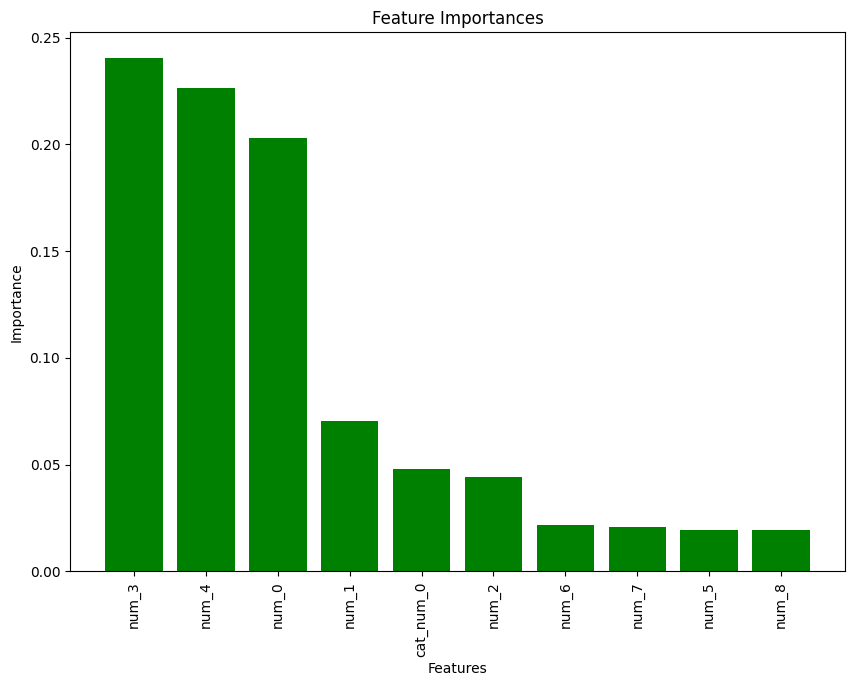

In [33]:
# Feature Importance plot
plt.figure(figsize = (10, 7))
plt.title("Feature Importances")
plt.bar(Ft_Importance_df_sorted["Feature"].head(10), Ft_Importance_df_sorted["Importance"].head(10), color = "green")
plt.xticks(ticks = range(0, len(Ft_Importance_df_sorted["Feature"].head(10))), labels = Ft_Importance_df_sorted["Feature"].head(10), rotation = 90)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

# Notes:

1. No duplicates detected
2. No null values detected
3. No outliers detected
4. All 20 features are cintinues variables
5. Most of features lies on the range bewteen 0.2 to 0.5 in the correlation matrix, showing a weak to moderate correlation.
6. All features will be selected to be included in the training process as result of previous point and also due to the scarcity of them and data points.

# 2. Pre-processing Data

As result of previous EDA, just 2 pre-processes will be performed on the data: scaling and the addition of polynimial features to increase the number of them, all by using pipeline ti facilitate the data preprocessing step.

In [44]:
# Class for ML pipeline

class ML_Pipeline():


    def __init__(self, num = True, catg = False):
        self.num = num # Pipeline for Numerical features
        self.catg = catg # Pipeline for categorical features

        if (self.num == True and self.catg == True) or (self.num == True and self.catg == False) or (self.num == False and self.catg == True):
            print(self.__str__())
        elif self.num == False and self.catg == False:
            raise ValueError("The ML pipeline must have either numerical values or categorical values")

    def __str__(self):
        return True

    # Creating the pre-processing pipelines

    # For Numerical features
    def numft_pipeline(self):

        # Pipeline for pre-processing
        self.pre_num = Pipeline([
        ("Scaling", StandardScaler()),
        ("PolFt", PolynomialFeatures())
        ])

        return self.pre_num

    # For categorical features
    def catgft_pipeline(self):

        # Pipeline for pre-processing
        self.pre_catg = Pipeline([
        ("OHE", OneHotEncoder())
        ])

        return self.pre_catg

    def prepro_pipeline(self, num_ft, catg_ft):


        preprocess = ColumnTransformer([
        ("Num_process", self.pre_num, num_ft),
        ("Catg_process", self.pre_catg, catg_ft)
        ])

        return preprocess

#3. Modeling and Training

In [45]:
#######
# Defining the dataset and Models for Regression
#######

# Dataset split

# Training and testing dataset
X_train, X_test, Y_train, Y_test = train_test_split(X, Y_reg, test_size = 0.2, shuffle = True, random_state = 5)

# Training and validation dataset
X_train_batch, X_val, Y_train_batch, Y_val = train_test_split(X_train, Y_train, test_size = 0.2, shuffle = True, random_state = 5)

In [ ]:
from sklearn.linear_model import LassoCV, RidgeCV, ElasticNetCV
from sklearn.feature_selection import SelectFromModel


# Creation of the pipeline

# Initialuzing class ML_pipeline
Full_pipeline = ML_Pipeline(num = True, catg = True)

# Initialiting transformation for numerical features
Full_pipeline.numft_pipeline()

# Initialiting transformation for categorical features
Full_pipeline.catgft_pipeline()

# Pre-processing
Preprocess = Full_pipeline.prepro_pipeline(num_ft = quant_ft[:-1], catg_ft = qual_ft[:-1])

# Baseline Regression Model
Base_RegModel = LinearRegression()

# Adding Preprocessing and Model to the Pipeline
Full_pipeline = Pipeline([
                          ("Preprocess", Preprocess),
                          #("Ft_selection", SelectFromModel(ElasticNetCV(l1_ratio = 0.9, alphas = None, cv = 2, max_iter = 1000, random_state = 5))),
                          #("Ft_selection", SelectFromModel(ElasticNetCV(l1_ratio = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0], alphas = None, cv = 2, max_iter = 1000, random_state = 5))),
                          ("Model", Base_RegModel)
                         ])

True


In [ ]:
# Training
Full_pipeline.fit(X,Y_reg)

Pipeline(steps=[('Preprocess',
                 ColumnTransformer(transformers=[('Num_process',
                                                  Pipeline(steps=[('Scaling',
                                                                   StandardScaler()),
                                                                  ('PolFt',
                                                                   PolynomialFeatures())]),
                                                  ['num_0', 'num_1', 'num_2',
                                                   'num_3', 'num_4', 'num_5',
                                                   'num_6', 'num_7', 'num_8',
                                                   'num_9']),
                                                 ('Catg_process',
                                                  Pipeline(steps=[('OHE',
                                                                   OneHotEncoder())]),
                                                  ['cat_str_0', 'cat_str_1',
                                                   'cat_str_2', 'cat_str_3',
                                                   'cat_str_4', 'cat_num_0',
                                                   'cat_num_1', 'cat_num_2',
                                                   'cat_num_3',
                                                   'cat_num_4'])])),
                ('Ft_selection',
                 SelectFromModel(estimator=ElasticNetCV(cv=2, l1_ratio=0.9,
                                                        random_state=5))),
                ('Model', LinearRegression())])

In [ ]:
Y_test_pred = Full_pipeline.predict(X_test)

In [ ]:
n_catg_features = (Preprocess.named_transformers_["Catg_process"].get_feature_names_out().shape[0])
n_num_features = (Preprocess.named_transformers_["Num_process"].get_feature_names_out().shape[0])

Total_n_features = n_catg_features + n_num_features
print(Total_n_features)

190


In [55]:
# Feature numbers per category
# preprocess_name = Name obtained from the sklearn pipeline "pipeline"
# category_name = Numerical or categorical values names "string"
def feature_calculation(preprocess_name, category_name):
    n_features = (preprocess_name.named_transformers_[category_name].get_feature_names_out().shape[0])
    return n_features

# Total features used after pre-processing
def total_features_calculation(preprocess_name):
    n_catg_features = feature_calculation(preprocess_name = preprocess_name, category_name = "Catg_process")
    n_num_features = feature_calculation(preprocess_name = preprocess_name, category_name = "Num_process")

    return n_catg_features + n_num_features

# Adjusted R2 Score
def adj_r2_score(r2, n_samples, n_features):
    return 1 - (1 - r2) * (n_samples - 1) / (n_samples - n_features - 1)

In [ ]:
# Metrics

from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, max_error

MAE_test = mean_absolute_error(Y_test, Y_test_pred)
MAPE_test = mean_absolute_percentage_error(Y_test, Y_test_pred)
RMSE_test = mean_squared_error(Y_test, Y_test_pred)
R2_test = r2_score(Y_test, Y_test_pred)
ADJ_R2_test = adj_r2_score(R2_test, X_test.shape[0], Total_n_features)
MAX_Error_test = max_error(Y_test, Y_test_pred)

print(f"MAE:{MAE_test:.2f}")
print(f"MAPE:{MAPE_test:.2f}")
print(f"RMSE:{RMSE_test:.2f}")
print(f"R2:{R2_test:.2f}")
print(f"ADJ_R2:{ADJ_R2_test:.2f}")
print(f"MAX Error:{MAX_Error_test:.2f}")

MAE:0.76
MAPE:1.61
RMSE:1.37
R2:0.94
ADJ_R2:0.92
MAX Error:15.04


In [ ]:
Base: No poly, no ft sel

MAE:2.92
MAPE:3.54
RMSE:16.89
R2:0.29
ADJ_R2:0.09
MAX Error:16.22

In [ ]:
With poly, no ft sel

MAE:0.72
MAPE:1.49
RMSE:1.22
R2:0.95
ADJ_R2:0.92
MAX Error:14.10

In [ ]:
No poly, with ft sel

MAE:3.01
MAPE:3.54
RMSE:17.36
R2:0.27
ADJ_R2:0.06
MAX Error:16.48

In [ ]:
With poly, with ft selec

MAE:0.74
MAPE:1.49
RMSE:1.30
R2:0.95
ADJ_R2:0.92
MAX Error:14.80

In [ ]:
!pip install mlflow
import mlflow

In [41]:
# Creating a database to save experiments' results
mlflow.set_tracking_uri(f"sqlite:///{Output_dir}/mlflow.db")

In [43]:
# mlflow DoE initialization
mlflow.set_experiment("Regression_experiment")

<Experiment: artifact_location='/content/mlruns/1', creation_time=1790357670837, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1790357670837, lifecycle_stage='active', name='Regression_experiment', tags={}, trace_location=None, workspace='default'>

In [34]:
seed = 5

In [50]:
#######
# Defining multiple Regression Models to compare their performance
#######

# ML models initialization and definition to be compared
models_reg = {
              "LinearRegression": LinearRegression(),
              "DecisionTree": DecisionTreeRegressor(max_depth = 6, random_state = seed)
              #"GradientBoosting": GradientBoostingRegressor(random_state = seed),
              #"NeuralNetwork": MLPRegressor(hidden_layer_sizes = (64,32), max_iter = 300, random_state = seed),
              #"XGBReg": XGBRegressor(random_state = seed)
              }

In [48]:
# Model Pipeline Definition
from sklearn.linear_model import LassoCV, RidgeCV, ElasticNetCV
from sklearn.feature_selection import SelectFromModel

def model_pipeline(preprocess, model):

    Full_pipeline = Pipeline([
                              ("Preprocess", preprocess),
                              #("Ft_selection", SelectFromModel(ElasticNetCV(l1_ratio = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0], alphas = None, cv = 2, max_iter = 1000, random_state = seed))),
                              ("Model", model)
                             ])
    return Full_pipeline

In [56]:
# New Implementation
# Training and predictions for baseline models

for name, model in models_reg.items():

    # Creation of the pipeline

    # Initializing class ML_pipeline
    Full_pipeline = ML_Pipeline(num = True, catg = True)

    # Initialiting transformation for numerical features
    Full_pipeline.numft_pipeline()

    # Initialiting transformation for categorical features
    Full_pipeline.catgft_pipeline()

    # Pre-processing
    Preprocess = Full_pipeline.prepro_pipeline(num_ft = quant_ft[:-1], catg_ft = qual_ft[:-1])

    # Adding Preprocessing and Model to the Pipeline
    Full_pipeline = model_pipeline(preprocess, model)

    # Model - Fitting
    Full_pipeline.fit(X_train_batch, Y_train_batch)

    # Predictions
    Y_train_batch_pred = Full_pipeline.predict(X_train_batch)
    Y_val_pred = Full_pipeline.predict(X_val)

    # Metrics
    # Validation
    MAE_val = mean_absolute_error(Y_val, Y_val_pred)
    MAPE_val = mean_absolute_percentage_error(Y_val, Y_val_pred)
    RMSE_val = mean_squared_error(Y_val, Y_val_pred)
    R2_val = r2_score(Y_val, Y_val_pred)
    ADJ_R2_val = adj_r2_score(R2_val, X_val.shape[0], Total_n_features)
    MAX_Error_val = max_error(Y_val, Y_val_pred)

print("Training process: Done\n")

print("\n=============== Models Results: Baseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)

> /tmp/ipykernel_2407/886824376.py(7)<cell line: 0>()
      5 
      6     # Creation of the pipeline
----> 7     breakpoint()
      8     # Initializing class ML_pipeline
      9     Full_pipeline = ML_Pipeline(num = True, catg = True)

ipdb> p model
LinearRegression()
ipdb> p name
'LinearRegression'
ipdb> Q
*** NameError: name 'Q' is not defined
ipdb> q


In [ ]:
# Training and predictions for baseline models

results_reg = [] # Empty list to save results

for name, model in models_reg.items():

    # Pipeline Definition
    preprocess = prepro_pipeline(features_name)
    Full_pipeline = model_pipeline(preprocess, model)

    Full_pipeline.fit(X_train, Y_train)
    Y_val_pred = Full_pipeline.predict(X_val)

    # Metrics
    rmse_val = mean_squared_error(Y_val, Y_val_pred)
    r2_val = r2_score(Y_val, Y_val_pred)

    # Saving results
    results_reg.append({"Model": name, "RMSE_val": rmse_val, "R2_val": r2_val})

# Creating a dataframe
results_reg = pd.DataFrame(results_reg)

print("Training process: Done\n")

print("\n=============== Models Results: Baseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Training process: Done


=============== Models Results: Baseline ===============

Regression Results:
              Model   RMSE_val    R2_val
0  LinearRegression  10.060612  0.607866
1      DecisionTree  11.281033  0.560298
2  GradientBoosting   4.136337  0.838777
3     NeuralNetwork   7.575847  0.704715
4            XGBReg   5.285514  0.793986


#4. Baseline Results

In [ ]:
# Printing results

print("\n=============== Models Results: Baseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)


=============== Models Results: Baseline ===============

Regression Results:
              Model   RMSE_val    R2_val
0  LinearRegression  10.125868  0.605323
1      DecisionTree  12.830899  0.499888
2  GradientBoosting   4.712220  0.816331
3     NeuralNetwork   9.048977  0.647297
4            XGBReg   6.384417  0.751154


In [ ]:
print("\n=============== Models Results: L1 Lasso Baseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)


=============== Models Results: L1 Lasso Baseline ===============

Regression Results:
              Model   RMSE_val    R2_val
0  LinearRegression  10.060612  0.607866
1      DecisionTree  11.281033  0.560298
2  GradientBoosting   4.136337  0.838777
3     NeuralNetwork   7.575847  0.704715
4            XGBReg   5.285514  0.793986


In [ ]:
print("\n=============== Models Results: L2 Ridge Baseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)


=============== Models Results: L2 Ridge Baseline ===============

Regression Results:
              Model   RMSE_val    R2_val
0  LinearRegression  10.177830  0.603297
1      DecisionTree  10.820375  0.578253
2  GradientBoosting   7.166416  0.720674
3     NeuralNetwork   5.804706  0.773749
4            XGBReg   7.109069  0.722909


In [ ]:
print("\n=============== Models Results: ElasticNet Baseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)


=============== Models Results: ElasticNet Baseline ===============

Regression Results:
              Model   RMSE_val    R2_val
0  LinearRegression  10.177830  0.603297
1      DecisionTree  10.820375  0.578253
2  GradientBoosting   7.166416  0.720674
3     NeuralNetwork   5.804706  0.773749
4            XGBReg   7.109069  0.722909


In [ ]:
print("\n=============== Models Results: Mod ElasticBetBaseline ===============")
print("\nRegression Results:")
pprint.pprint(results_reg)


=============== Models Results: Mod ElasticBetBaseline ===============

Regression Results:
              Model   RMSE_val    R2_val
0  LinearRegression  10.060612  0.607866
1      DecisionTree  11.281033  0.560298
2  GradientBoosting   4.136337  0.838777
3     NeuralNetwork   7.575847  0.704715
4            XGBReg   5.285514  0.793986


#5. Model Optimization and Results

In [ ]:
# Function to tune hyperparaneters via GridSearch

def grid_tuning_models(pipeline, params, cv, scoring, x, y):

    # Training
    start = time()
    grid = GridSearchCV(
                        estimator = pipeline,
                        param_grid = params,
                        cv = cv,
                        n_jobs = -1,
                        verbose = 0,
                        scoring = scoring
                        )

    grid.fit(x, y)
    end = time()

    return grid, (end-start)

In [ ]:
# Defining all Regression models hyperparameters to be tested

# Hyperparameters Linear Regression
param_grid_LR = {"Model__fit_intercept": [False, True]}

# Hyperparameters Decision Tree
param_grid_DT = {
                 "Model__max_depth": [None, 3, 5, 7, 10],
                 "Model__min_samples_split": [2, 5, 10],
                 "Model__min_samples_leaf": [1, 2, 4],
                 "Model__max_features": [None, "sqrt", "log2"]
                }

# Hyperparameters GradientBoosting
param_grid_GB = {
                 "Model__n_estimators": [100, 200],
                 "Model__learning_rate": [0.1, 0.2],
                 "Model__max_depth": [3, 6, 9],
                 "Model__min_samples_split": [2, 4],
                 "Model__min_samples_leaf": [1, 2]
                }

# Hyperparameters Neural Network
param_grid_MLP = {
                  "Model__hidden_layer_sizes": [(16, 8), (32, 16), (64, 32)],
                  "Model__alpha": [0.001, 0.01],
                  "Model__learning_rate_init": [0.01, 0.1],
                  "Model__max_iter": [200, 300]
                 }

# Hyperparameters XGBoost
param_grid_XGB = {
                  "Model__n_estimators": [100, 200],
                  "Model__learning_rate": [0.05, 0.1],
                  "Model__max_depth": [3, 6, 9],
                  "Model__subsample": [0.8, 1.0],
                  "Model__reg_alpha": [0.0, 0.1],
                  "Model__reg_lambda": [1.0, 2.0]
                 }

params_grid_r = [param_grid_LR, param_grid_DT, param_grid_GB, param_grid_MLP, param_grid_XGB]

In [ ]:
## Tunning hyperprameters based on training data

N_results = []

print("\nTesting the models and finding the best hyperparameters\n")

i = 0
for name, model in models_reg.items():

    # Checking the performance of the model with 2 number if folds and 1 repeats (these numbers were selected to reduced the training time validation)
    cv = RepeatedKFold(n_splits = 2, n_repeats = 1, random_state = 5)

    print(f"Running: {name}")
    # Pipeline Definition
    preprocess = prepro_pipeline(features_name)
    Full_pipeline = model_pipeline(preprocess, model)

    # Tuning (DoE)
    grid, tr_time = grid_tuning_models(pipeline = Full_pipeline, params = params_grid_r[i],
                                    cv = cv, scoring = "r2", x = X_train, y = Y_train)
    # Getting the best model
    best_model = grid.best_estimator_

    # Evaluation
    Y_val_pred = best_model.predict(X_val)

    # Metric evaluation

    r2_train = grid.best_score_
    rmse_val = mean_squared_error(Y_val, Y_val_pred)
    r2_val= r2_score(Y_val, Y_val_pred)

    # Saving results
    N_results.append({"Model and Parameters": grid.best_estimator_["Model"], "RMSE_val": rmse_val, "R2_val": r2_val, "R2_train": r2_train, "Training time (s)": tr_time} )

    i += 1

# Creating a dataframe
N_results_r = pd.DataFrame(N_results)

print("Training process: Done\n")


Testing the models and finding the best hyperparameters

Running: LinearRegression
Running: DecisionTree
Running: GradientBoosting
Running: NeuralNetwork
Running: XGBReg
Training process: Done



In [ ]:
# Printing results

print("\n=============== Models Results: Optimized ===============")
print("\nRegression Results:")
pprint.pprint(N_results_r)


=============== Models Results: Optimized ===============

Regression Results:
                                Model and Parameters   RMSE_val    R2_val  \
0                                 LinearRegression()   6.706394  0.738604   
1  DecisionTreeRegressor(max_depth=5, min_samples...  12.091738  0.528699   
2  ([DecisionTreeRegressor(criterion='friedman_ms...   4.572264  0.821786   
3  MLPRegressor(alpha=0.01, hidden_layer_sizes=(6...  16.757852  0.346827   
4  XGBRegressor(base_score=None, booster=None, ca...   4.157684  0.837945   

   R2_train  Training time (s)  
0  0.449799           3.599480  
1  0.538988           8.271578  
2  0.786354         733.276062  
3 -0.111028          12.646836  
4  0.797658        1750.884991  


In [ ]:
# Learning curves

def lr_curve(model, X, Y, cv, scoring = "r2"):

    train_sizes, train_scores, val_scores = learning_curve(
                                                           estimator = model,
                                                           X = Xtrain,
                                                           y = Ytrain,
                                                           cv = cv,
                                                           scoring = "r2",
                                                           train_sizes = np.linspace(0.1, 1.0, 10),
                                                           n_jobs = -1
                                                          )

    # Getting scores
    train_mean = train_scores.mean(axis = 1)
    train_std = train_scores.std(axis = 1)

    val_mean = val_scores.mean(axis = 1)
    val_std = val_scores.std(axis = 1)

    return train_sizes, train_scores, val_scores, train_mean, train_std, val_mean, val_std

In [ ]:
# Extracting the best model of all by considering
# the highest R2 with the lowest RMSE as second metric,
# which is the GradientBossting model.
# XGBoosg offers similar performance, however the training time
# was the final factor to select GradientBoostint.

# GradientBoost Regressor Model
Best_Model_of_all = N_results_r.to_numpy()[2][0]

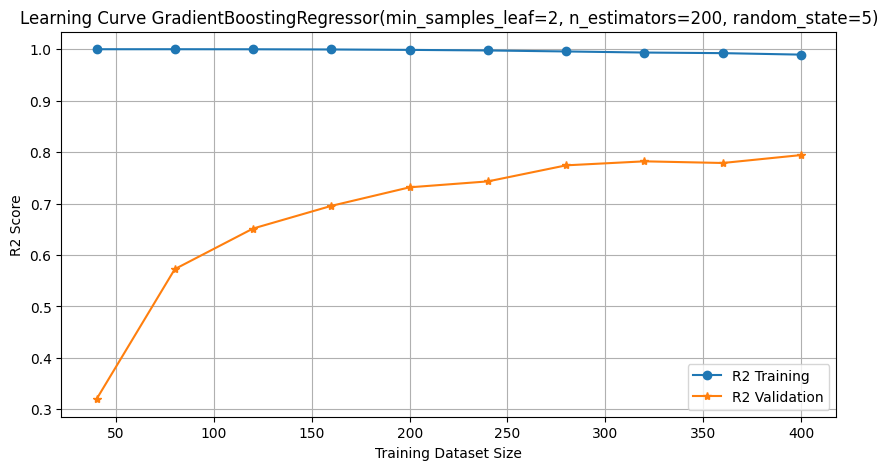

In [ ]:
## Plotting learning curves for the model selected

# Getting the values
train_sizes, train_scores, val_scores, train_mean, train_std, val_mean, val_std = lr_curve(model = Best_Model_of_all, X = Xtrain, Y = Ytrain, cv = cv)

# Plotting

plt.figure(figsize = (10, 5))

plt.plot(train_sizes, train_mean, "o-", label = "R2 Training")
plt.plot(train_sizes, val_mean, "*-", label = "R2 Validation")
plt.xlabel("Training Dataset Size")
plt.ylabel("R2 Score")
plt.title(f"Learning Curve {Best_Model_of_all}")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
Std_dev_val = val_std.mean()
Std_dev_val

np.float64(0.01442633743182829)

The model shows a good performance, with R2 = 0.82 and a std = 0.014. Additionally, the mean R2 training and validation values are really close each other, demonstrating no overfitting a no exceeding the 0.92 noise level described, showing a strong model.

#6. Test Data Evaluation

In [ ]:
## Blind/Test data evaluation

# Pipeline Definition
preprocess = prepro_pipeline(features_name)
Full_pipeline = model_pipeline(preprocess, Best_Model_of_all)

Full_pipeline.fit(X_train, Y_train)

# Evaluation
Y_test_pred = Full_pipeline.predict(X_test)

# Extracting and converting results to csv
target_pred_data = pd.DataFrame(Y_test_pred, columns = ["target_pred"])

target_pred_data.to_csv(f"/{Output_dir}/target_pred_data.csv", index = False)

print("CSV created")

CSV created


In [ ]:
target_pred_data

,target_pred
0,12.189402
1,12.452731
2,16.720224
3,13.000295
4,17.851925
...,...
195,11.431244
196,11.418215
197,10.558275
198,15.811029
